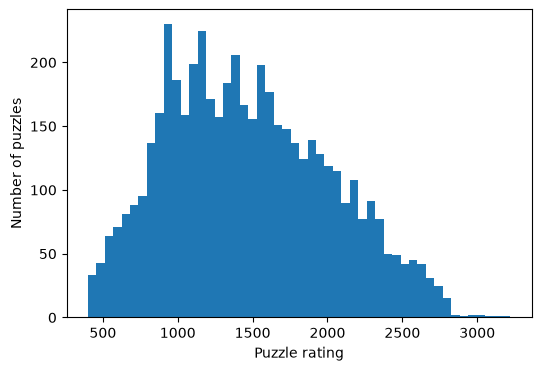

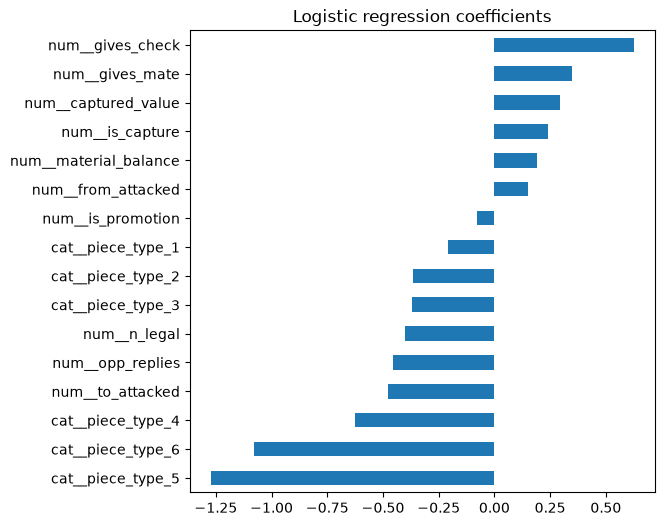

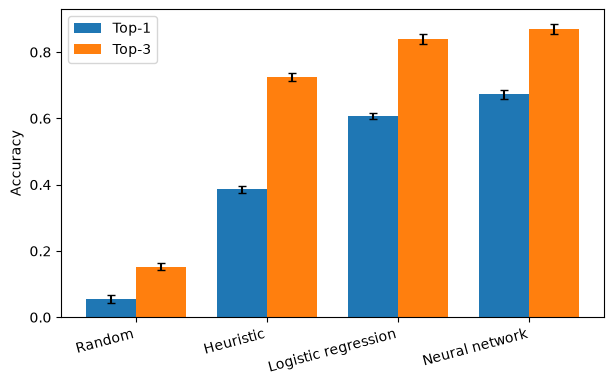

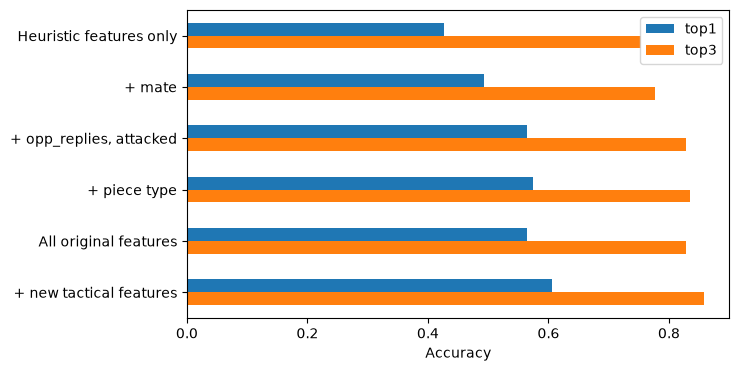

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

Path("figures").mkdir(exist_ok=True)

def esc(s):
    return str(s).replace("_", r"\_").replace("%", r"\%")

def save_tex(rows, header, path):
    lines = [r"\begin{tabular}{l" + "r" * (len(header) - 1) + "}", r"\hline",
             " & ".join(esc(h) for h in header) + r" \\", r"\hline"]
    for r in rows:
        lines.append(" & ".join(esc(c) for c in r) + r" \\")
    lines += [r"\hline", r"\end{tabular}"]
    Path(path).write_text("\n".join(lines))

# Figure 1: rating distribution
df = pd.read_csv("data/puzzles_sample.csv", dtype=str, keep_default_na=False)
df["Rating"] = pd.to_numeric(df["Rating"])
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df["Rating"], bins=50)
ax.set_xlabel("Puzzle rating"); ax.set_ylabel("Number of puzzles")
fig.savefig("figures/fig1_rating_distribution.png", dpi=200, bbox_inches="tight")

# Figure 2: logistic regression coefficients (single split)
coefs = pd.read_csv("results/coefficients.csv", index_col=0)["coefficient"]
fig, ax = plt.subplots(figsize=(6, 6))
coefs.plot.barh(ax=ax)
ax.set_title("Logistic regression coefficients")
fig.savefig("figures/fig2_coefficients.png", dpi=200, bbox_inches="tight")

# Figure 3: main results, mean and std over 5 splits
rep = pd.read_csv("results/repeated_splits.csv")
order = ["Random", "Heuristic", "Logistic regression", "Neural network"]
summ = rep.groupby("model")[["top1", "top3"]].agg(["mean", "std"]).loc[order]
fig, ax = plt.subplots(figsize=(7, 4))
x = list(range(len(order))); w = 0.38
ax.bar([i - w / 2 for i in x], summ[("top1", "mean")], w,
       yerr=summ[("top1", "std")], capsize=3, label="Top-1")
ax.bar([i + w / 2 for i in x], summ[("top3", "mean")], w,
       yerr=summ[("top3", "std")], capsize=3, label="Top-3")
ax.set_xticks(x); ax.set_xticklabels(order, rotation=15, ha="right")
ax.set_ylabel("Accuracy"); ax.legend()
fig.savefig("figures/fig3_main_results.png", dpi=200, bbox_inches="tight")

# Figure 4: feature-group ablation (single split)
abl = pd.read_csv("results/ablation.csv", index_col=0)
ax = abl.plot.barh(figsize=(7, 4))
ax.invert_yaxis(); ax.set_xlabel("Accuracy")
ax.figure.savefig("figures/fig4_ablation.png", dpi=200, bbox_inches="tight")

# Table 1: main results (mean ± std over 5 splits, in %)
s = summ * 100
rows = [[m,
         fr"{s.loc[m, ('top1', 'mean')]:.1f} $\pm$ {s.loc[m, ('top1', 'std')]:.1f}",
         fr"{s.loc[m, ('top3', 'mean')]:.1f} $\pm$ {s.loc[m, ('top3', 'std')]:.1f}"]
        for m in order]
save_tex(rows, ["Model", "Top-1 (%)", "Top-3 (%)"], "results/table_main.tex")

# Table 2: ablation (single split, in %)
a = abl * 100
rows = [[name, f"{r['top1']:.1f}", f"{r['top3']:.1f}"] for name, r in a.iterrows()]
save_tex(rows, ["Features", "Top-1 (%)", "Top-3 (%)"], "results/table_ablation.tex")

plt.show()

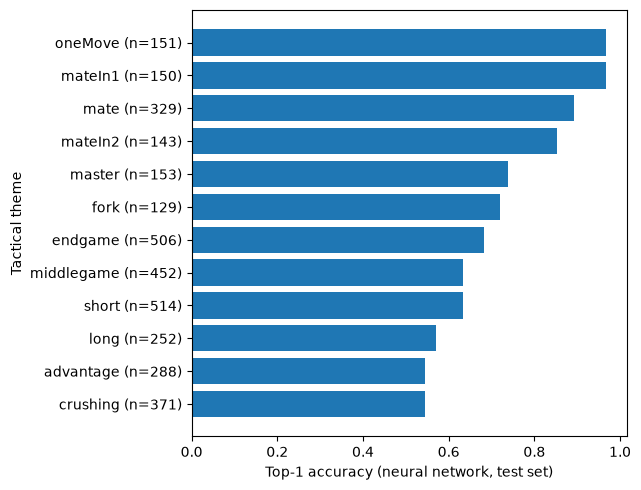

In [2]:
by_theme = pd.read_csv("results/errors_by_theme.csv", index_col=0)
top = by_theme.sort_values("n", ascending=False).head(12).sort_values("top1")
labels = [f"{theme} (n={n})" for theme, n in zip(top.index, top["n"])]

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.barh(labels, top["top1"])
ax.set_xlabel("Top-1 accuracy (neural network, test set)")
ax.set_ylabel("Tactical theme")
fig.tight_layout()
fig.savefig("figures/fig5_errors_by_theme.png", dpi=200)
plt.show()